# Fourth Practice

### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336

###### The use of AI has been greatly limited. No text has been written by AI, it's use has been limited to being an editor or a mistake checker. The places where AI has been used (a few plots) has been added aswell as the prompt that generated that code.

In [1]:
# Necessary libraries
import numpy as np
import math
import matplotlib.pyplot as plt

### 1. Finishing the example

We want to apply Sequential Quadratic Optimization to the problem:

$$
\begin{aligned}
\text{minimize} \quad & f(x_1, x_2) = e^{3x_1} + e^{-4x_2} \\
\text{subject to} \quad & h(x_1, x_2) = x_1^2 + x_2^2 - 1 = 0
\end{aligned}
$$

starting at $x^0 = (-1, 1)^T$, $\lambda^0 = -1$. The reference solution is $(x_1^*, x_2^*) \approx (-0.74834, 0.66332)^T$, $\lambda^* \approx -0.21233$.

#### Derivatives

$$
\nabla f = \begin{pmatrix} 3e^{3x_1} \\ -4e^{-4x_2} \end{pmatrix} \qquad
\nabla^2 f = \begin{pmatrix} 9e^{3x_1} & 0 \\ 0 & 16e^{-4x_2} \end{pmatrix} \qquad
\nabla h = \begin{pmatrix} 2x_1 \\ 2x_2 \end{pmatrix} \qquad
\nabla^2 h = \begin{pmatrix} 2 & 0 \\ 0 & 2 \end{pmatrix}
$$

$$
\mathcal{L}(x, \lambda) = f(x) - \lambda h(x) \qquad
\nabla_x \mathcal{L} = \nabla f - \lambda \nabla h \qquad
\nabla^2_{xx} \mathcal{L} = \nabla^2 f - \lambda \nabla^2 h
$$

In [2]:
# Claude prompt: look at lab4.pdf, I want to do the exercise 1, complete the notebook with it
def f(x):
    return np.exp(3*x[0]) + np.exp(-4*x[1])

def grad_f(x):
    return np.array([3*np.exp(3*x[0]), -4*np.exp(-4*x[1])])

def hess_f(x):
    return np.array([[9*np.exp(3*x[0]), 0],
                     [0, 16*np.exp(-4*x[1])]])

def h(x):
    return x[0]**2 + x[1]**2 - 1

def grad_h(x):
    return np.array([2*x[0], 2*x[1]])

def hess_h(x):
    return np.array([[2, 0],
                     [0, 2]])

def grad_L(x, lam):
    return grad_f(x) - lam*grad_h(x)

def hess_L(x, lam):
    return hess_f(x) - lam*hess_h(x)

#### Newton step on the Lagrangian (KKT system)

$$
\begin{pmatrix} \nabla^2_{xx}\mathcal{L}(x^k, \lambda^k) & -\nabla h(x^k) \\ -\nabla h(x^k)^T & 0 \end{pmatrix}
\begin{pmatrix} d^k \\ \nu^k \end{pmatrix}
=
\begin{pmatrix} -\nabla_x \mathcal{L}(x^k, \lambda^k) \\ h(x^k) \end{pmatrix}
\qquad
\begin{pmatrix} x^{k+1} \\ \lambda^{k+1} \end{pmatrix} = \begin{pmatrix} x^{k} \\ \lambda^{k} \end{pmatrix} + \alpha^k \begin{pmatrix} d^k \\ \nu^k \end{pmatrix}
$$

In [3]:
# Claude prompt: look at lab4.pdf, I want to do the exercise 1, complete the notebook with it
# Builds the 3x3 matrix and the right hand side of the KKT system (Eq. 2)
def kkt_system(x, lam):
    gh = grad_h(x)
    A = np.zeros((3, 3))
    A[:2, :2] = hess_L(x, lam)
    A[:2, 2] = -gh
    A[2, :2] = -gh
    b = np.concatenate([-grad_L(x, lam), [h(x)]])
    return A, b

# First iteration, to compare with the values of the example
x0 = np.array([-1.0, 1.0])
lam0 = -1.0

A0, b0 = kkt_system(x0, lam0)
sol0 = np.linalg.solve(A0, b0)
d0, nu0 = sol0[:2], sol0[2]

np.set_printoptions(precision=5, suppress=True)
print("grad f     =", grad_f(x0))
print("grad h     =", grad_h(x0))
print("grad_x L   =", grad_L(x0, lam0))
print("hess f     =\n", hess_f(x0))
print("hess_xx L  =\n", hess_L(x0, lam0))
print("KKT matrix =\n", A0)
print("RHS        =", b0)
print("d0         =", d0)
print(f"nu0        = {nu0:.5f}")
print("x1         =", x0 + d0)
print(f"lambda1    = {lam0 + nu0:.5f}")

grad f     = [ 0.14936 -0.07326]
grad h     = [-2.  2.]
grad_x L   = [-1.85064  1.92674]
hess f     =
 [[0.44808 0.     ]
 [0.      0.29305]]
hess_xx L  =
 [[2.44808 0.     ]
 [0.      2.29305]]
KKT matrix =
 [[ 2.44808  0.       2.     ]
 [ 0.       2.29305 -2.     ]
 [ 2.      -2.       0.     ]]
RHS        = [ 1.85064 -1.92674  1.     ]
d0         = [ 0.22577 -0.27423]
nu0        = 0.64896
x1         = [-0.77423  0.72577]
lambda1    = -0.35104


> **TODO (our comments):** compare the first iteration with the values given in the example.

### 1.1 SQP with $\alpha^k = 1$

Stopping condition: $\|\nabla_x \mathcal{L}(x^k, \lambda^k)\| < \text{tol}$.

In [4]:
# Claude prompt: look at lab4.pdf, I want to do the exercise 1, complete the notebook with it
def sqp(x0, lam0=-1.0, alpha=1.0, tol=1e-6, max_iter=100):
    x = np.array(x0, dtype=float)
    lam = lam0
    path_x, path_lam = [x.copy()], [lam]
    norms_gradL, abs_h = [np.linalg.norm(grad_L(x, lam))], [abs(h(x))]
    for k in range(max_iter):
        # Stopping condition over grad_x L
        if norms_gradL[-1] < tol:
            break
        A, b = kkt_system(x, lam)
        sol = np.linalg.solve(A, b)
        d, nu = sol[:2], sol[2]
        x = x + alpha*d
        lam = lam + alpha*nu
        path_x.append(x.copy())
        path_lam.append(lam)
        norms_gradL.append(np.linalg.norm(grad_L(x, lam)))
        abs_h.append(abs(h(x)))
    return np.array(path_x), np.array(path_lam), np.array(norms_gradL), np.array(abs_h)

In [5]:
# Claude prompt: look at lab4.pdf, I want to do the exercise 1, complete the notebook with it
path_x, path_lam, norms_gradL, abs_h = sqp(x0, lam0, alpha=1.0, tol=1e-6)

print(f"{'k':>3} | {'x1':>10} | {'x2':>10} | {'lambda':>10} | {'||grad_x L||':>12} | {'|h(x)|':>10} | {'f(x)':>8}")
print("-" * 82)
for k in range(len(path_x)):
    print(f"{k:>3} | {path_x[k,0]:>10.6f} | {path_x[k,1]:>10.6f} | {path_lam[k]:>10.6f} | {norms_gradL[k]:>12.3e} | {abs_h[k]:>10.3e} | {f(path_x[k]):>8.5f}")

  k |         x1 |         x2 |     lambda | ||grad_x L|| |     |h(x)| |     f(x)
----------------------------------------------------------------------------------
  0 |  -1.000000 |   1.000000 |  -1.000000 |    2.672e+00 |  1.000e+00 |  0.06810
  1 |  -0.774226 |   0.725774 |  -0.351038 |    3.827e-01 |  1.262e-01 |  0.15286
  2 |  -0.748645 |   0.666139 |  -0.216059 |    1.110e-02 |  4.211e-03 |  0.17546
  3 |  -0.748338 |   0.663323 |  -0.212324 |    3.945e-06 |  8.021e-06 |  0.17634
  4 |  -0.748335 |   0.663320 |  -0.212325 |    3.105e-11 |  1.631e-11 |  0.17635


In [6]:
#LIMPIAR


# Claude prompt: look at lab4.pdf, I want to do the exercise 1, complete the notebook with it
x_ref = np.array([-0.74834, 0.66332])
lam_ref = -0.21233
x_star, lam_star = path_x[-1], path_lam[-1]

print(f"Iterations: {len(path_x) - 1}")
print(f"x*      = ({x_star[0]:.5f}, {x_star[1]:.5f})    reference ({x_ref[0]}, {x_ref[1]})")
print(f"lambda* = {lam_star:.5f}               reference {lam_ref}")
print(f"f(x*)   = {f(x_star):.5f}")
print(f"h(x*)   = {h(x_star):.2e}")

# Error of each iterate w.r.t. the final point; e_{k+1}/e_k^2 ~ constant means quadratic convergence
errors = np.linalg.norm(np.column_stack([path_x - x_star, path_lam - lam_star]), axis=1)
print("\nError ||(x^k, lambda^k) - (x*, lambda*)||:", " ".join(f"{e:.3e}" for e in errors[:-1]))
print("Ratio e_{k+1} / e_k^2:                    ", " ".join(f"{r:.5f}" for r in errors[1:-1] / errors[:-2]**2))

# Saddle point check: eigenvalues of the full Hessian of L in (x, lambda)
A_star, _ = kkt_system(x_star, lam_star)
print("\nEigenvalues of the Hessian of L (x, lambda):", np.linalg.eigvalsh(A_star))
print("Eigenvalues of hess_xx L:                   ", np.linalg.eigvalsh(hess_L(x_star, lam_star)))

# Curvature of L along the constraint: t is the tangent to the circle h(x) = 0 at x*
gh = grad_h(x_star)
t = np.array([-gh[1], gh[0]]) / np.linalg.norm(gh)
print(f"t^T hess_xx L t (tangent direction):         {t @ hess_L(x_star, lam_star) @ t:.5f}")

Iterations: 4
x*      = (-0.74834, 0.66332)    reference (-0.74834, 0.66332)
lambda* = -0.21232               reference -0.21233
f(x*)   = 0.17635
h(x*)   = 1.63e-11

Error ||(x^k, lambda^k) - (x*, lambda*)||: 8.928e-01 1.543e-01 4.688e-03 4.168e-06
Ratio e_{k+1} / e_k^2:                     0.19359 0.19689 0.18963

Eigenvalues of the Hessian of L (x, lambda): [-1.40179  1.47234  2.85881]
Eigenvalues of hess_xx L:                    [1.37799 1.55137]
t^T hess_xx L t (tangent direction):         1.47508


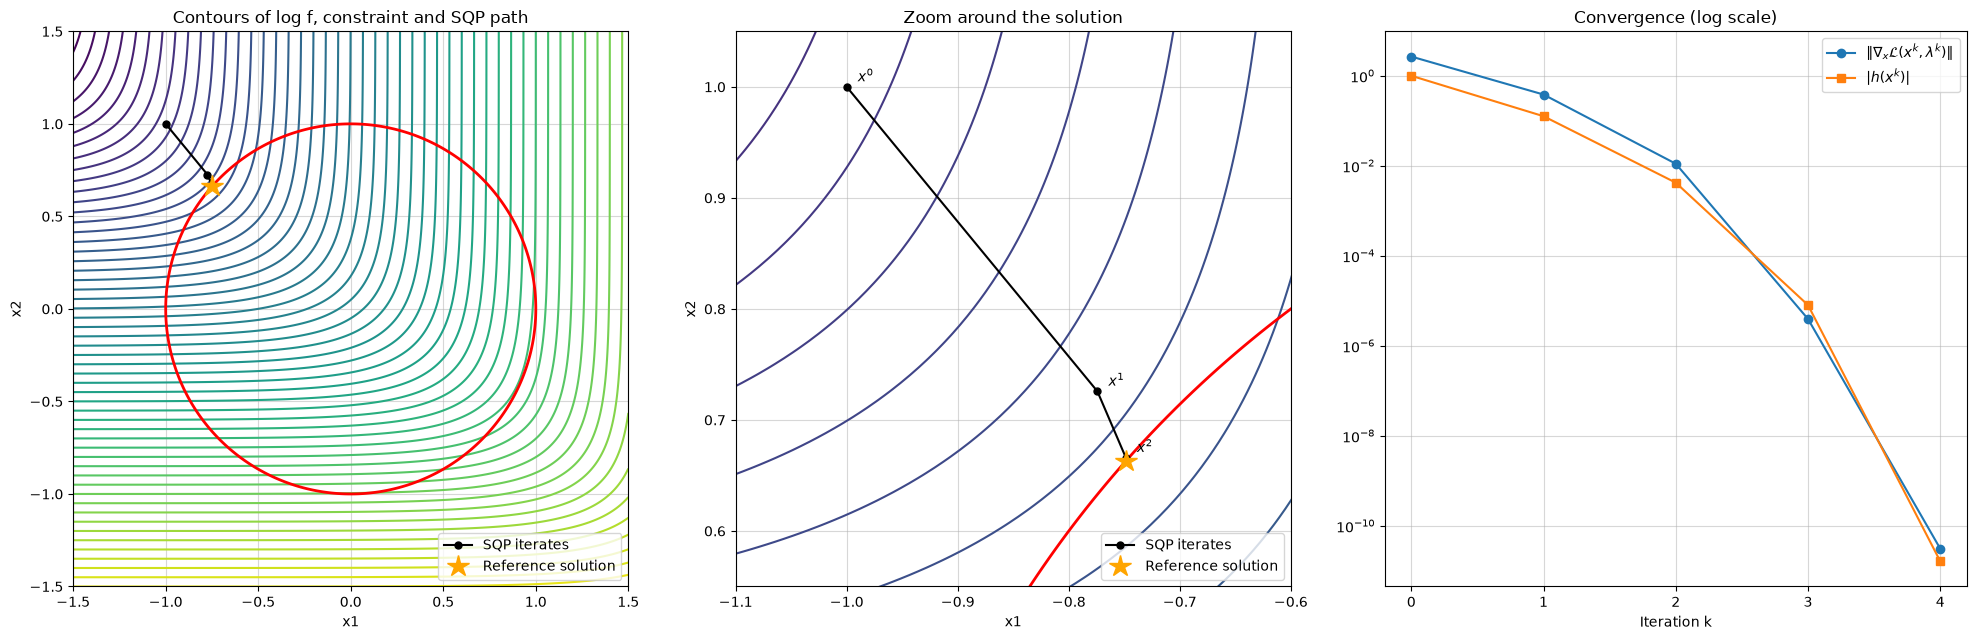

In [7]:
# Claude prompt: look at lab4.pdf, I want to do the exercise 1, complete the notebook with it
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Fg = np.exp(3*x1g) + np.exp(-4*x2g)
Hg = x1g**2 + x2g**2 - 1

fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))

# Full view: contours of log f (f grows exponentially), constraint and SQP path
for ax, lims, title in [(axs[0], (-1.5, 1.5, -1.5, 1.5), "Contours of log f, constraint and SQP path"),
                        (axs[1], (-1.1, -0.6, 0.55, 1.05), "Zoom around the solution")]:
    ax.contour(x1g, x2g, np.log(Fg), levels=60, cmap="viridis")
    ax.contour(x1g, x2g, Hg, levels=[0], colors="red", linewidths=2)
    ax.plot(path_x[:, 0], path_x[:, 1], "o-", color="black", ms=5, label="SQP iterates")
    for k in range(3 if ax is axs[1] else 0):
        ax.annotate(f"$x^{k}$", path_x[k], textcoords="offset points", xytext=(8, 4))
    ax.plot(*x_ref, "*", color="orange", ms=16, zorder=3, label="Reference solution")
    ax.set_xlim(lims[0], lims[1])
    ax.set_ylim(lims[2], lims[3])
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)
    ax.grid(alpha=0.5)
    ax.legend(loc="lower right")

# Convergence of the stopping quantity and of the infeasibility
ks = np.arange(len(norms_gradL))
axs[2].semilogy(ks, norms_gradL, "o-", label=r"$\|\nabla_x \mathcal{L}(x^k, \lambda^k)\|$")
axs[2].semilogy(ks, abs_h, "s-", label=r"$|h(x^k)|$")
axs[2].set_xticks(ks)
axs[2].set_xlabel("Iteration k")
axs[2].set_title("Convergence (log scale)")
axs[2].grid(alpha=0.5)
axs[2].legend()

plt.tight_layout()
plt.show()

> **TODO (our comments):** discuss the convergence (number of iterations, quadratic rate), feasibility of the iterates, and the saddle point vs. the curvature along the constraint.

### 1.2 Starting points farther from the solution

$$
x^0 = (0.5, -0.25)^T \qquad x^0 = (1.2, -1)^T \qquad x^0 = (1, 1)^T \qquad \lambda^0 = -1
$$

In [8]:
# Claude prompt: make the experiment 2 starting from (0.5, -0,25) and from (1.2,-1)
# Claude prompt (edit): add a new point in (1,1)
def print_sqp_table(path_x, path_lam, norms_gradL, abs_h):
    print(f"{'k':>3} | {'x1':>10} | {'x2':>10} | {'lambda':>10} | {'||grad_x L||':>12} | {'|h(x)|':>10} | {'f(x)':>8}")
    print("-" * 82)
    for k in range(len(path_x)):
        print(f"{k:>3} | {path_x[k,0]:>10.6f} | {path_x[k,1]:>10.6f} | {path_lam[k]:>10.6f} | {norms_gradL[k]:>12.3e} | {abs_h[k]:>10.3e} | {f(path_x[k]):>8.5f}")

starting_points = {"(-1, 1)": np.array([-1.0, 1.0]),
                   "(0.5, -0.25)": np.array([0.5, -0.25]),
                   "(1.2, -1)": np.array([1.2, -1.0]),
                   "(1, 1)": np.array([1.0, 1.0])}

results_sqp = {}
for name, x_start in starting_points.items():
    results_sqp[name] = sqp(x_start, lam0=-1.0, alpha=1.0, tol=1e-6)

for name in ["(0.5, -0.25)", "(1.2, -1)", "(1, 1)"]:
    print(f"\nStarting point x0 = {name}, lambda0 = -1")
    print_sqp_table(*results_sqp[name])


Starting point x0 = (0.5, -0.25), lambda0 = -1
  k |         x1 |         x2 |     lambda | ||grad_x L|| |     |h(x)| |     f(x)
----------------------------------------------------------------------------------
  0 |   0.500000 |  -0.250000 |  -1.000000 |    1.838e+01 |  6.875e-01 |  7.19997
  1 |   1.094750 |  -0.435500 |  38.623937 |    1.171e+01 |  3.881e-01 | 32.39772
  2 |   0.942169 |  -0.373432 |  25.212768 |    3.309e+00 |  2.713e-02 | 21.34003
  3 |   0.909618 |  -0.419228 |  25.130054 |    3.978e-01 |  3.157e-03 | 20.66433
  4 |   0.910364 |  -0.413844 |  25.291562 |    6.666e-03 |  2.954e-05 | 20.58469
  5 |   0.910413 |  -0.413700 |  25.293854 |    4.127e-06 |  2.306e-08 | 20.58394
  6 |   0.910413 |  -0.413700 |  25.293855 |    1.554e-12 |  8.438e-15 | 20.58394

Starting point x0 = (1.2, -1), lambda0 = -1
  k |         x1 |         x2 |     lambda | ||grad_x L|| |     |h(x)| |     f(x)
----------------------------------------------------------------------------------
  0

In [9]:
# Claude prompt: make the experiment 2 starting from (0.5, -0,25) and from (1.2,-1)
# Curvature of L along the constraint at the final point (t is the tangent to the circle)
def tangent_curvature(x, lam):
    gh = grad_h(x)
    t = np.array([-gh[1], gh[0]]) / np.linalg.norm(gh)
    return t @ hess_L(x, lam) @ t

print(f"{'x0':>13} | {'Iter':>4} | {'x1*':>9} | {'x2*':>9} | {'lambda*':>9} | {'f(x*)':>8} | {'|h(x*)|':>9} | {'||x* - x_ref||':>14} | {'t^T H t':>8}")
print("-" * 107)
for name, (px, pl, ng, ah) in results_sqp.items():
    xs, ls = px[-1], pl[-1]
    print(f"{name:>13} | {len(px) - 1:>4} | {xs[0]:>9.5f} | {xs[1]:>9.5f} | {ls:>9.5f} | {f(xs):>8.5f} | {ah[-1]:>9.2e} | {np.linalg.norm(xs - x_ref):>14.5f} | {tangent_curvature(xs, ls):>8.4f}")

           x0 | Iter |       x1* |       x2* |   lambda* |    f(x*) |   |h(x*)| | ||x* - x_ref|| |  t^T H t
-----------------------------------------------------------------------------------------------------------
      (-1, 1) |    4 |  -0.74834 |   0.66332 |  -0.21232 |  0.17635 |  1.63e-11 |        0.00000 |   1.4751
 (0.5, -0.25) |    6 |   0.91041 |  -0.41370 |  25.29386 | 20.58394 |  8.44e-15 |        1.97773 |  42.4446
    (1.2, -1) |    7 |   0.91041 |  -0.41370 |  25.29386 | 20.58394 |  7.83e-12 |        1.97773 |  42.4446
       (1, 1) |    9 |  -0.74834 |   0.66332 |  -0.21232 |  0.17635 |  3.04e-09 |        0.00000 |   1.4751


In [10]:
# Claude prompt: make the experiment 2 starting from (0.5, -0,25) and from (1.2,-1)
# f restricted to the constraint: x = (cos theta, sin theta)
theta = np.linspace(-np.pi, np.pi, 200001)
g_theta = np.exp(3*np.cos(theta)) + np.exp(-4*np.sin(theta))
dg_theta = -3*np.sin(theta)*np.exp(3*np.cos(theta)) - 4*np.cos(theta)*np.exp(-4*np.sin(theta))

# KKT points of the problem = points where the derivative along the circle changes sign
idx = np.where(np.sign(dg_theta[:-1]) != np.sign(dg_theta[1:]))[0]
kkt_minima = [theta[i] for i in idx if dg_theta[i] < 0]
kkt_maxima = [theta[i] for i in idx if dg_theta[i] > 0]
print("KKT points of f on the circle:")
for th in sorted(kkt_minima + kkt_maxima):
    kind = "local min" if th in kkt_minima else "local max"
    print(f"  theta = {np.degrees(th):>8.3f} deg   x = ({np.cos(th):>8.5f}, {np.sin(th):>8.5f})   f = {np.exp(3*np.cos(th)) + np.exp(-4*np.sin(th)):>8.5f}   {kind}")

KKT points of f on the circle:
  theta =  -89.179 deg   x = ( 0.01433, -0.99990)   f = 55.61966   local max
  theta =  -24.439 deg   x = ( 0.91041, -0.41372)   f = 20.58394   local min
  theta =   -5.742 deg   x = ( 0.99498, -0.10005)   f = 21.27758   local max
  theta =  138.445 deg   x = (-0.74832,  0.66334)   f =  0.17635   local min


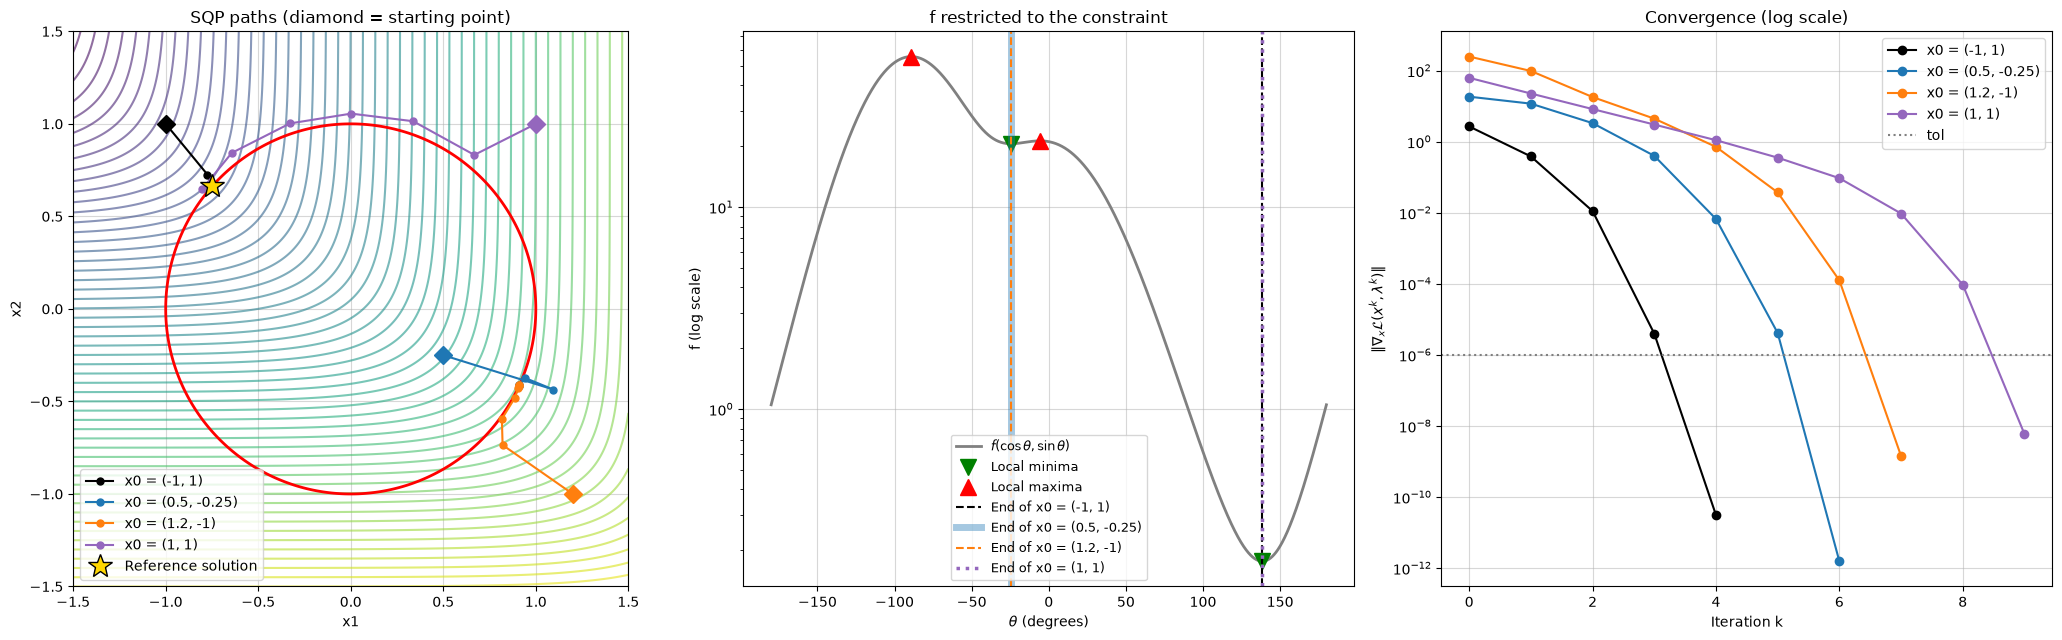

In [11]:
# Claude prompt: make the experiment 2 starting from (0.5, -0,25) and from (1.2,-1)
# Claude prompt (edit): add a new point in (1,1)
colors_sqp = {"(-1, 1)": "black", "(0.5, -0.25)": "tab:blue", "(1.2, -1)": "tab:orange", "(1, 1)": "tab:purple"}

fig, axs = plt.subplots(1, 3, figsize=(21, 6.5))

# Paths over the contours of log f
ax = axs[0]
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
ax.contour(x1g, x2g, np.log(np.exp(3*x1g) + np.exp(-4*x2g)), levels=60, cmap="viridis", alpha=0.6)
ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
for name, (px, pl, ng, ah) in results_sqp.items():
    ax.plot(px[:, 0], px[:, 1], "o-", color=colors_sqp[name], ms=5, label=f"x0 = {name}")
    ax.plot(*px[0], "D", color=colors_sqp[name], ms=9)
ax.plot(*x_ref, "*", color="gold", mec="black", ms=18, zorder=3, label="Reference solution")
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("SQP paths (diamond = starting point)")
ax.grid(alpha=0.5)
ax.legend(loc="lower left")

# f along the circle and where each run ends
ax = axs[1]
ax.semilogy(np.degrees(theta), g_theta, color="gray", lw=2, label=r"$f(\cos\theta, \sin\theta)$")
ax.plot(np.degrees(kkt_minima), np.exp(3*np.cos(kkt_minima)) + np.exp(-4*np.sin(kkt_minima)), "v", color="green", ms=11, label="Local minima")
ax.plot(np.degrees(kkt_maxima), np.exp(3*np.cos(kkt_maxima)) + np.exp(-4*np.sin(kkt_maxima)), "^", color="red", ms=11, label="Local maxima")
# (0.5, -0.25) and (1.2, -1) end at the same point, so the first one is drawn wider underneath
line_styles = {"(-1, 1)": ("--", 1.5, 1.0), "(0.5, -0.25)": ("-", 5, 0.4), "(1.2, -1)": ("--", 1.5, 1.0), "(1, 1)": (":", 2.5, 1.0)}
for name, (px, pl, ng, ah) in results_sqp.items():
    th_end = np.arctan2(px[-1, 1], px[-1, 0])
    ls, lw, alpha = line_styles[name]
    ax.axvline(np.degrees(th_end), color=colors_sqp[name], ls=ls, lw=lw, alpha=alpha, label=f"End of x0 = {name}")
ax.set_xlabel(r"$\theta$ (degrees)")
ax.set_ylabel("f (log scale)")
ax.set_title("f restricted to the constraint")
ax.grid(alpha=0.5)
ax.legend(loc="lower center", fontsize=9)

# Convergence of the stopping criterion
ax = axs[2]
for name, (px, pl, ng, ah) in results_sqp.items():
    ax.semilogy(np.arange(len(ng)), ng, "o-", color=colors_sqp[name], label=f"x0 = {name}")
ax.axhline(1e-6, color="gray", ls=":", label="tol")
ax.set_xlabel("Iteration k")
ax.set_ylabel(r"$\|\nabla_x \mathcal{L}(x^k, \lambda^k)\|$")
ax.set_title("Convergence (log scale)")
ax.grid(alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

> **TODO (our comments):** discuss to which point each starting point converges, the value of $\lambda$ and $f$ there, and why Newton's method does not guarantee reaching the global solution.

### 1.3 Merit function: gradient descent with backtracking

Instead of applying Newton directly, we first minimize the quadratic penalty (merit) function with $\rho = 10$:

$$
\mathcal{M}(x) = f(x) + \rho\, h(x)^2 \qquad
\nabla \mathcal{M}(x) = \nabla f(x) + 2\rho\, h(x)\, \nabla h(x)
$$

We reuse `grad_desc_backtracking` from Sessions 2 and 3 with two changes:
- The search direction is the normalized gradient $p^k = \nabla \mathcal{M}(x^k) / \|\nabla \mathcal{M}(x^k)\|$, so $\alpha^k$ is directly the length of the step and huge gradients (the exponentials of $f$) do not produce huge jumps.
- As in Session 3, if $\alpha$ reaches `alpha_min` without decreasing $\mathcal{M}$, we stop.

At every iteration $\alpha$ starts at 1 and is halved until $\mathcal{M}(x^k - \alpha^k p^k) < \mathcal{M}(x^k)$. We stop when $\|\nabla \mathcal{M}(x^k)\| < 10^{-5}$.

At a minimizer of $\mathcal{M}$ we have $\nabla f = -2\rho h \nabla h$, which compared with the KKT condition $\nabla f = \lambda \nabla h$ gives the estimate $\lambda \approx -2\rho\, h(x)$.

In [12]:
# Claude prompt: we want to do experiment 3. we want to use backtracking, use (and lightly modify accordingly) the functions from Session 3 and Session 2
rho = 10

def M(x):
    return f(x) + rho*h(x)**2

def grad_M(x):
    return grad_f(x) + 2*rho*h(x)*grad_h(x)

# Claude prompt (edit): experiment 4, add an optional stop_condition to switch to Newton
# Session 2 version (reset alpha every iteration) + Session 3 stop when alpha_min is reached + normalized gradient
def grad_desc_backtracking(f, grad_f, x0, alpha0=1, reset=True, normalize=True, tol=1e-5, max_iter=10000, alpha_min=1e-8, stop_condition=None):
    x = np.array(x0, dtype=float)
    path = [x]
    alphas = []
    n_halvings = 0
    alpha = alpha0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        if stop_condition is not None and stop_condition(k, x, grad): # extra stopping rule (used in 1.4 to switch to Newton)
            break
        p = grad / np.linalg.norm(grad) if normalize else grad
        if reset:
            alpha = alpha0
        while f(x - alpha * p) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        if f(x - alpha * p) >= f(x): # if no advances are made and alpha has reached its minimum
            break
        x = x - alpha * p
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

In [13]:
# Claude prompt: we want to do experiment 3. we want to use backtracking, use (and lightly modify accordingly) the functions from Session 3 and Session 2
results_merit = {}
for name, x_start in starting_points.items():
    results_merit[name] = grad_desc_backtracking(M, grad_M, x_start)

print(f"Merit function with rho = {rho}, stopping criterion: ||grad M(x)|| < 1e-5\n")
print(f"{'x0':>13} | {'Iter':>5} | {'halvings':>8} | {'x1':>9} | {'x2':>9} | {'||grad M||':>10} | {'h(x)':>9} | {'f(x)':>8} | {'-2 rho h':>9} | {'||x - x_ref||':>13}")
print("-" * 121)
for name, (px, alphas, n_halv) in results_merit.items():
    xm = px[-1]
    print(f"{name:>13} | {len(px) - 1:>5} | {n_halv:>8} | {xm[0]:>9.5f} | {xm[1]:>9.5f} | {np.linalg.norm(grad_M(xm)):>10.2e} | "
          f"{h(xm):>9.5f} | {f(xm):>8.5f} | {-2*rho*h(xm):>9.5f} | {np.linalg.norm(xm - x_ref):>13.5f}")
print(f"\nReference: x* = ({x_ref[0]}, {x_ref[1]}), lambda* = {lam_ref}, f(x*) = {f(x_ref):.5f}")

Merit function with rho = 10, stopping criterion: ||grad M(x)|| < 1e-5

           x0 |  Iter | halvings |        x1 |        x2 | ||grad M|| |      h(x) |     f(x) |  -2 rho h | ||x - x_ref||
-------------------------------------------------------------------------------------------------------------------------
      (-1, 1) |   265 |     3892 |  -0.75243 |   0.66654 |   4.37e-07 |   0.01043 |  0.17415 |  -0.20859 |       0.00521
 (0.5, -0.25) |   288 |     3559 |  -0.75243 |   0.66654 |   1.20e-06 |   0.01043 |  0.17415 |  -0.20859 |       0.00521
    (1.2, -1) |   285 |     3775 |  -0.75243 |   0.66654 |   7.09e-07 |   0.01043 |  0.17415 |  -0.20859 |       0.00521
       (1, 1) |   227 |     2616 |  -0.75243 |   0.66654 |   2.04e-06 |   0.01043 |  0.17415 |  -0.20859 |       0.00521

Reference: x* = (-0.74834, 0.66332), lambda* = -0.21233, f(x*) = 0.17635


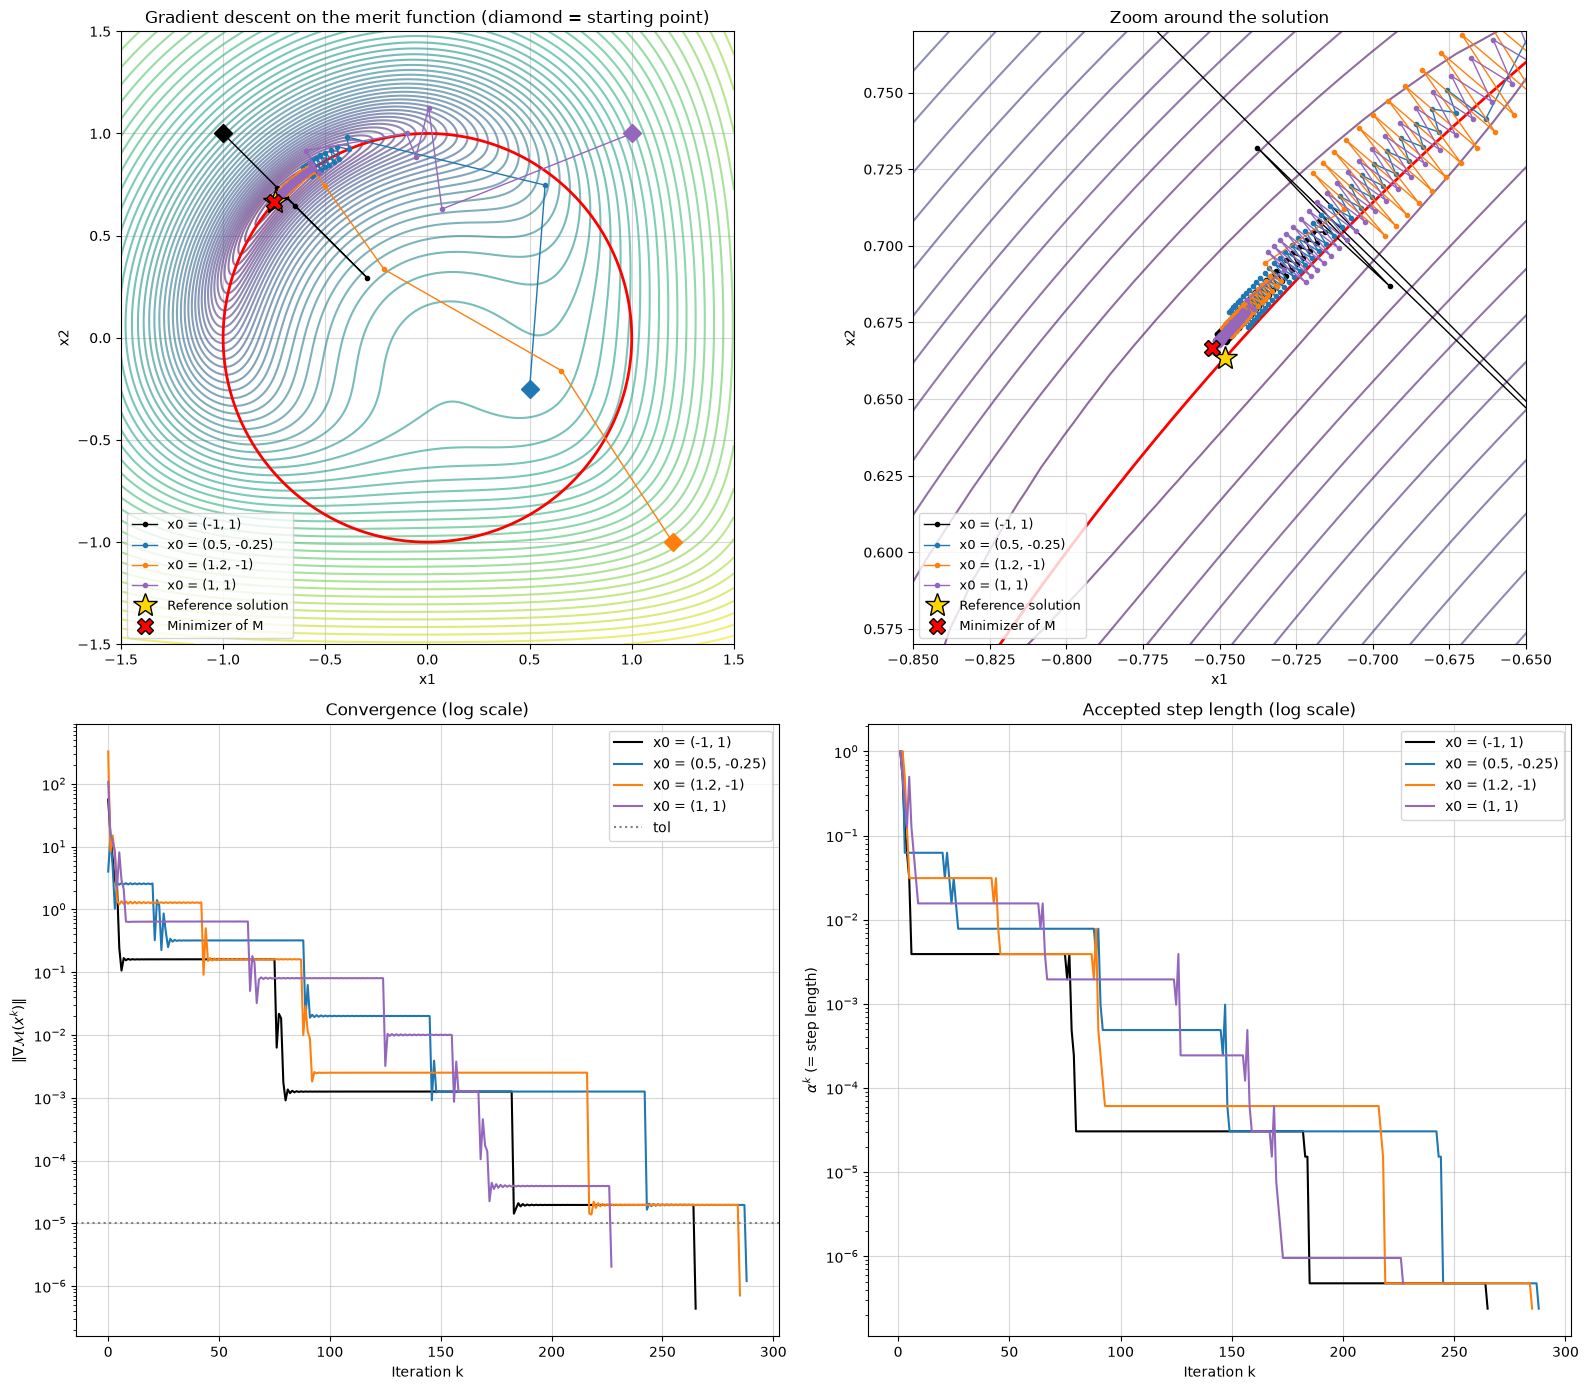

In [14]:
# Claude prompt: we want to do experiment 3. we want to use backtracking, use (and lightly modify accordingly) the functions from Session 3 and Session 2
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

fig, axs = plt.subplots(2, 2, figsize=(16, 14))

# Paths over the contours of log M, full view and zoom
for ax, lims, title in [(axs[0, 0], (-1.5, 1.5, -1.5, 1.5), "Gradient descent on the merit function (diamond = starting point)"),
                        (axs[0, 1], (-0.85, -0.65, 0.57, 0.77), "Zoom around the solution")]:
    ax.contour(x1g, x2g, np.log(Mg), levels=60, cmap="viridis", alpha=0.6)
    ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
    for name, (px, alphas, n_halv) in results_merit.items():
        ax.plot(px[:, 0], px[:, 1], "o-", color=colors_sqp[name], ms=3, lw=1, label=f"x0 = {name}")
        ax.plot(*px[0], "D", color=colors_sqp[name], ms=9)
    ax.plot(*x_ref, "*", color="gold", mec="black", ms=18, zorder=3, label="Reference solution")
    ax.plot(*results_merit["(-1, 1)"][0][-1], "X", color="red", mec="black", ms=12, zorder=4, label="Minimizer of M")
    ax.set_xlim(lims[0], lims[1])
    ax.set_ylim(lims[2], lims[3])
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)
    ax.grid(alpha=0.5)
    ax.legend(loc="lower left", fontsize=9)

# Convergence of ||grad M|| and accepted step lengths
for name, (px, alphas, n_halv) in results_merit.items():
    axs[1, 0].semilogy(np.arange(len(px)), [np.linalg.norm(grad_M(x)) for x in px], color=colors_sqp[name], label=f"x0 = {name}")
    axs[1, 1].semilogy(np.arange(1, len(alphas) + 1), alphas, color=colors_sqp[name], label=f"x0 = {name}")
axs[1, 0].axhline(1e-5, color="gray", ls=":", label="tol")
axs[1, 0].set_ylabel(r"$\|\nabla \mathcal{M}(x^k)\|$")
axs[1, 0].set_title("Convergence (log scale)")
axs[1, 1].set_ylabel(r"$\alpha^k$ (= step length)")
axs[1, 1].set_title("Accepted step length (log scale)")
for ax in axs[1]:
    ax.set_xlabel("Iteration k")
    ax.grid(alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

> **TODO (our comments):** discuss whether every starting point reaches the same point, how far the minimizer of $\mathcal{M}$ is from the reference solution (it is not feasible: $h(x) 
eq 0$), the estimate $\lambda pprox -2
ho h(x)$, and the behaviour of the step length.

### 1.4 Merit function + Newton (SQP)

We start with the gradient descent with backtracking on $\mathcal{M}$ of 1.3 and, once a switch condition holds, we continue with the SQP Newton iteration of 1.1 ($\alpha^k = 1$, stopping when $\|\nabla_x \mathcal{L}\| < 10^{-6}$). We try three switch conditions:

- **Distance:** $\|x^k - x_{\text{ref}}\| < 0.4$
- **Steps:** $k = 10$ gradient steps done
- **Tolerance:** $\|\nabla_x \mathcal{L}(x^k, \hat\lambda^k)\| < 10\mathrm{e}{-1} = 1$, the same quantity used as stopping criterion in Newton. As we do not have a multiplier during the gradient phase, we use the least squares one, the $\lambda$ that best satisfies $\nabla f = \lambda \nabla h$:

$$\hat\lambda^k = \frac{\nabla h(x^k)^T \nabla f(x^k)}{\|\nabla h(x^k)\|^2}$$

(With $\lambda = -2\rho h(x)$ instead, $\nabla_x \mathcal{L} = \nabla f + 2\rho h \nabla h = \nabla \mathcal{M}$, which would be the same as checking the gradient of the merit function.)

Each condition is a parameter of `merit_then_newton` (`None` = not used). If several are given, we switch as soon as any of them holds. The initial multiplier for Newton is the estimate from 1.3, $\lambda^0 = -2\rho\, h(x^{\text{switch}})$, unless `lam0` is given.

In [15]:
# Claude prompt (edit): distance to 0.4, steps to 10, tolerance on the gradient of the Lagrangian (least squares lambda)
# Claude prompt: now we want to do experiment 4: try 3 switch conditions to the newton method (switch_distance = 0.25, switch_steps = 30, switch_tolerance = 10e-1), make the function so we can change this parameters easily
def merit_then_newton(x0, switch_distance=None, switch_steps=None, switch_tol=None, lam0=None,
                      x_ref=x_ref, tol_newton=1e-6, max_iter_gd=10000):
    # Least squares multiplier: the lambda that best satisfies grad f = lambda grad h
    def lam_ls(x):
        gh = grad_h(x)
        return gh @ grad_f(x) / (gh @ gh)

    def switch(k, x, grad):
        return ((switch_distance is not None and np.linalg.norm(x - x_ref) < switch_distance) or
                (switch_steps is not None and k >= switch_steps) or
                (switch_tol is not None and np.linalg.norm(grad_L(x, lam_ls(x))) < switch_tol))

    # Phase 1: gradient descent with backtracking on the merit function
    path_gd, alphas, n_halvings = grad_desc_backtracking(M, grad_M, x0, max_iter=max_iter_gd, stop_condition=switch)
    x_switch = path_gd[-1]

    # Phase 2: Newton (SQP with alpha = 1) from the switch point
    if lam0 is None:
        lam0 = -2*rho*h(x_switch)
    path_x, path_lam, norms_gradL, abs_h = sqp(x_switch, lam0=lam0, alpha=1.0, tol=tol_newton)
    return {"path_gd": path_gd, "n_halvings": n_halvings, "lam0": lam0,
            "path_x": path_x, "path_lam": path_lam, "norms_gradL": norms_gradL, "abs_h": abs_h}

In [16]:
# Claude prompt (edit): distance to 0.4, steps to 10, tolerance on the gradient of the Lagrangian (least squares lambda)
# Claude prompt: now we want to do experiment 4: try 3 switch conditions to the newton method (switch_distance = 0.25, switch_steps = 30, switch_tolerance = 10e-1), make the function so we can change this parameters easily
switch_distance = 0.4
switch_steps = 7
switch_tolerance = 10e-1

switch_options = {f"distance < {switch_distance}": dict(switch_distance=switch_distance),
                  f"steps = {switch_steps}": dict(switch_steps=switch_steps),
                  f"||grad_x L|| < {switch_tolerance}": dict(switch_tol=switch_tolerance)}

results_hybrid = {opt: {name: merit_then_newton(x_start, **kwargs) for name, x_start in starting_points.items()}
                  for opt, kwargs in switch_options.items()}

for opt, res in results_hybrid.items():
    print(f"\nSwitch condition: {opt}")
    print(f"{'x0':>13} | {'GD iter':>7} | {'x switch':>20} | {'||x_sw - x_ref||':>16} | {'lambda0':>8} | {'Newton iter':>11} | {'x*':>20} | {'lambda*':>9} | {'||grad_x L||':>12}")
    print("-" * 137)
    for name, r in res.items():
        xs, xe = r["path_gd"][-1], r["path_x"][-1]
        print(f"{name:>13} | {len(r['path_gd']) - 1:>7} | {f'({xs[0]:.5f}, {xs[1]:.5f})':>20} | {np.linalg.norm(xs - x_ref):>16.5f} | {r['lam0']:>8.4f} | "
              f"{len(r['path_x']) - 1:>11} | {f'({xe[0]:.5f}, {xe[1]:.5f})':>20} | {r['path_lam'][-1]:>9.5f} | {r['norms_gradL'][-1]:>12.2e}")
print(f"\nReference: x* = ({x_ref[0]}, {x_ref[1]}), lambda* = {lam_ref}")


Switch condition: distance < 0.4
           x0 | GD iter |             x switch | ||x_sw - x_ref|| |  lambda0 | Newton iter |                   x* |   lambda* | ||grad_x L||
-----------------------------------------------------------------------------------------------------------------------------------------
      (-1, 1) |       2 |  (-0.64785, 0.64504) |          0.10214 |   3.2842 |           4 |  (-0.74834, 0.66332) |  -0.21232 |     6.50e-07
 (0.5, -0.25) |       5 |  (-0.43191, 0.87434) |          0.38034 |   0.9797 |          13 |  (-0.74834, 0.66332) |  -0.21232 |     1.66e-07
    (1.2, -1) |       3 |  (-0.50140, 0.74300) |          0.25948 |   3.9310 |           5 |  (-0.74834, 0.66332) |  -0.21232 |     3.30e-07
       (1, 1) |       5 |  (-0.59518, 0.91636) |          0.29578 |  -3.8792 |           5 |  (-0.74834, 0.66332) |  -0.21232 |     1.35e-08

Switch condition: steps = 7
           x0 | GD iter |             x switch | ||x_sw - x_ref|| |  lambda0 | Newton iter |  

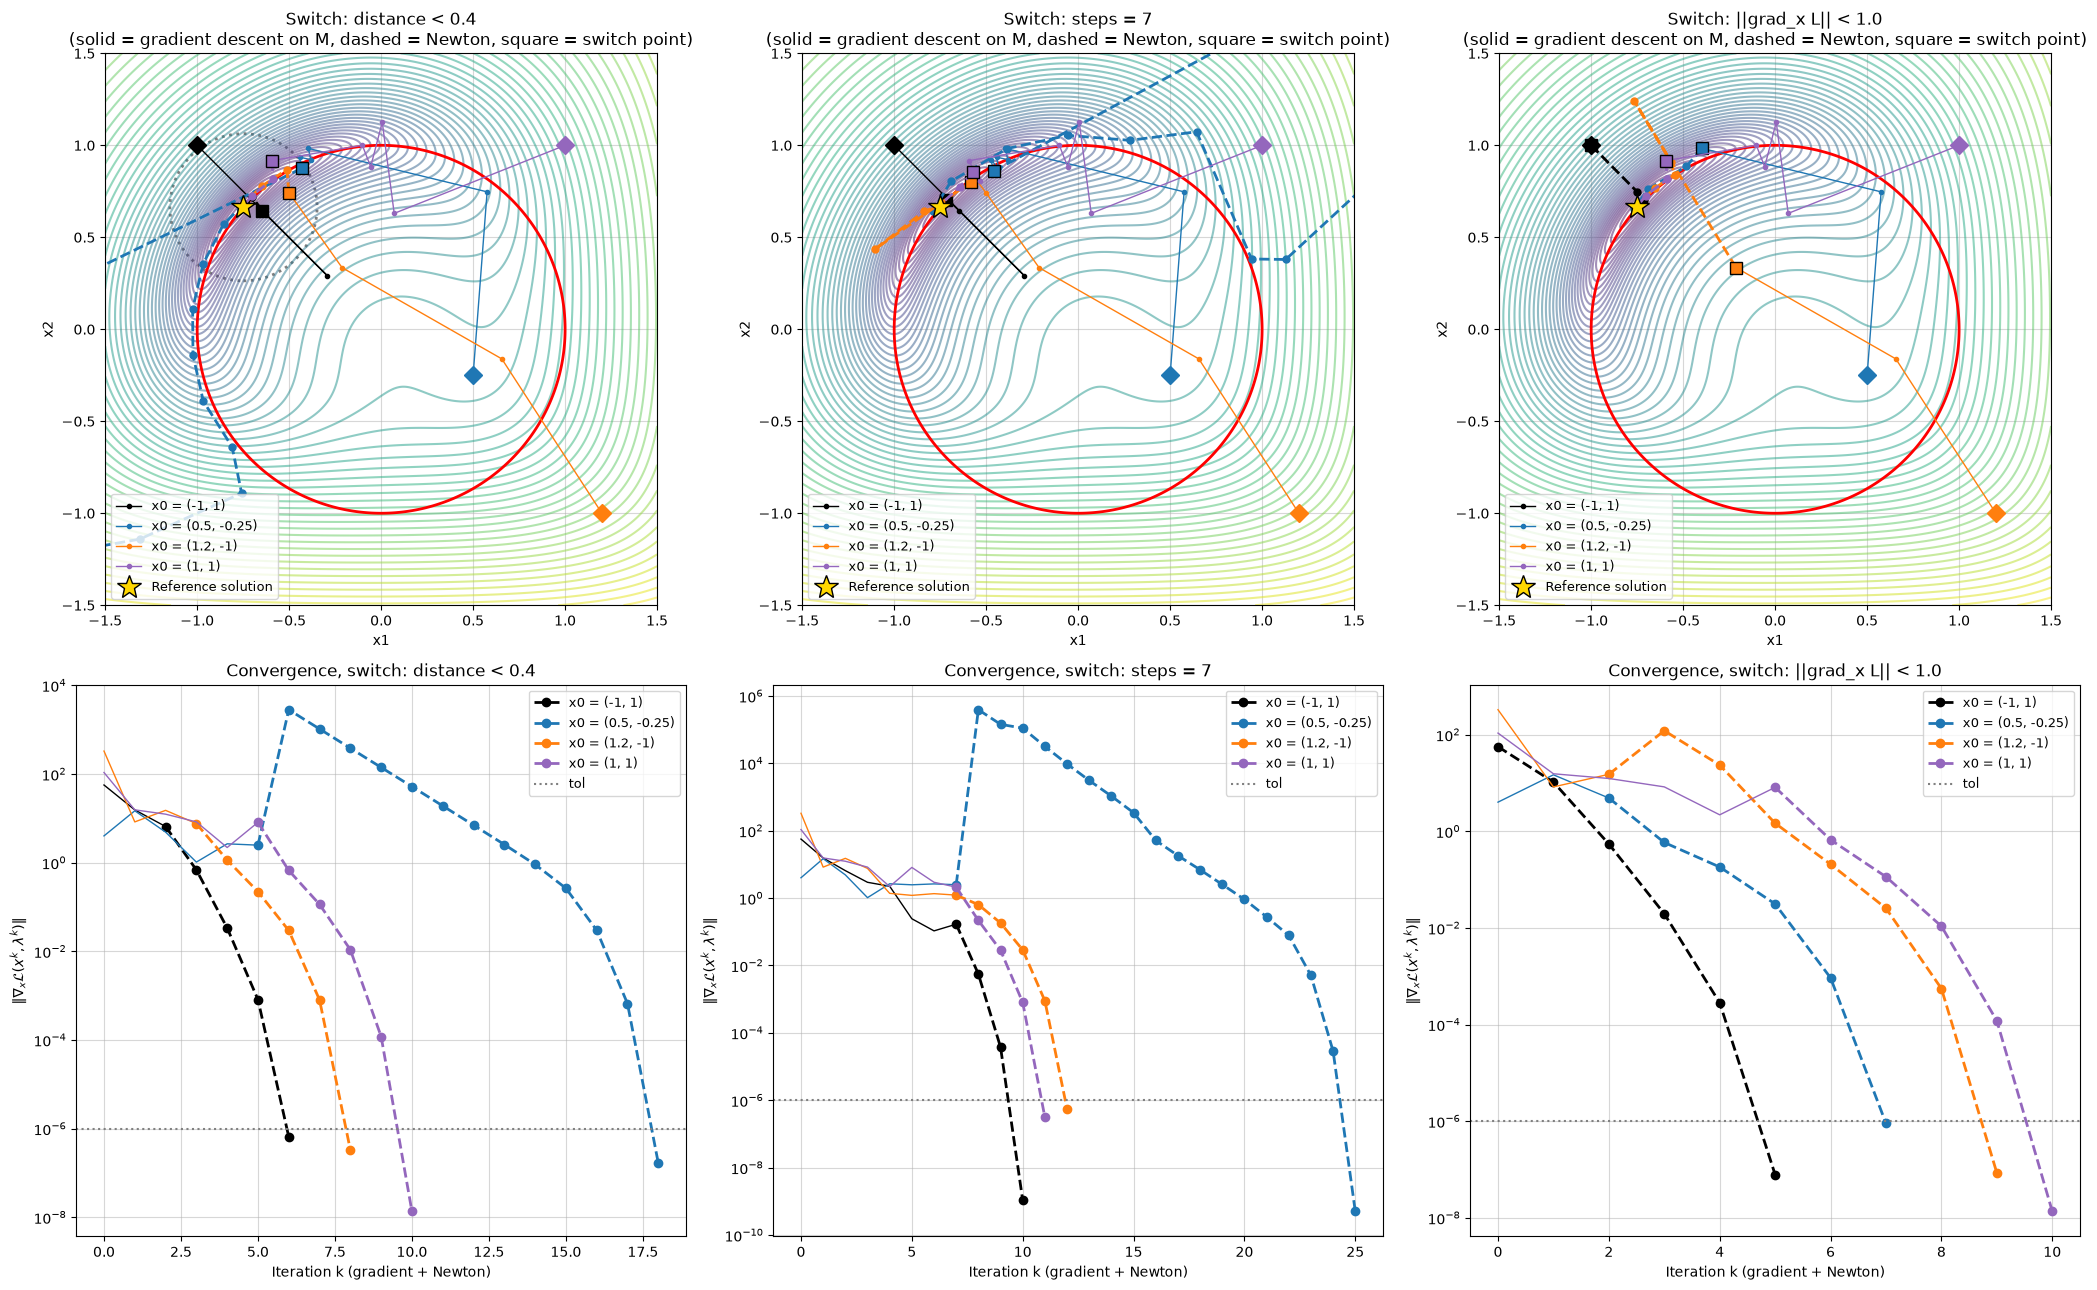

In [17]:
# Claude prompt: now we want to do experiment 4: try 3 switch conditions to the newton method (switch_distance = 0.25, switch_steps = 30, switch_tolerance = 10e-1), make the function so we can change this parameters easily
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

fig, axs = plt.subplots(2, 3, figsize=(21, 13))
for j, (opt, res) in enumerate(results_hybrid.items()):
    # Paths: solid = gradient descent on M, dashed = Newton
    ax = axs[0, j]
    ax.contour(x1g, x2g, np.log(Mg), levels=60, cmap="viridis", alpha=0.5)
    ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
    if "distance" in opt:
        ax.add_patch(plt.Circle(x_ref, switch_distance, fill=False, ls=":", color="gray", lw=2))
    for name, r in res.items():
        pg, px = r["path_gd"], r["path_x"]
        ax.plot(pg[:, 0], pg[:, 1], "o-", color=colors_sqp[name], ms=3, lw=1, label=f"x0 = {name}")
        ax.plot(px[:, 0], px[:, 1], "o--", color=colors_sqp[name], ms=5, lw=2)
        ax.plot(*pg[0], "D", color=colors_sqp[name], ms=9)
        ax.plot(*pg[-1], "s", color=colors_sqp[name], mec="black", ms=8)
    ax.plot(*x_ref, "*", color="gold", mec="black", ms=18, zorder=3, label="Reference solution")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f"Switch: {opt}\n(solid = gradient descent on M, dashed = Newton, square = switch point)")
    ax.grid(alpha=0.5)
    ax.legend(loc="lower left", fontsize=9)

    # Convergence: ||grad_x L|| along the whole run (gradient phase uses lambda = -2 rho h(x))
    ax = axs[1, j]
    for name, r in res.items():
        pg = r["path_gd"]
        ng_gd = [np.linalg.norm(grad_L(x, -2*rho*h(x))) for x in pg]
        n_gd = len(pg) - 1
        ax.semilogy(np.arange(n_gd + 1), ng_gd, "-", color=colors_sqp[name], lw=1)
        ax.semilogy(np.arange(n_gd, n_gd + len(r["norms_gradL"])), r["norms_gradL"], "o--", color=colors_sqp[name], lw=2, label=f"x0 = {name}")
    ax.axhline(1e-6, color="gray", ls=":", label="tol")
    ax.set_xlabel("Iteration k (gradient + Newton)")
    ax.set_ylabel(r"$\|\nabla_x \mathcal{L}(x^k, \lambda^k)\|$")
    ax.set_title(f"Convergence, switch: {opt}")
    ax.grid(alpha=0.5)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [18]:
# Claude prompt: add a cell below that shows the value of the hessian at the steps around the switch point
# Claude prompt (edit): add a column that says if the hessian is positive definite, use 3 decimals and fix the column spacing
# Hessian of the Lagrangian hess_xx L = hess f - lambda hess h at the last gradient steps, the switch point and the first Newton steps.
# In the gradient phase there is no multiplier, so we use the estimate lambda = -2 rho h(x) (the one given to Newton at the switch).
# t^T H t is the curvature along the tangent of the circle (tangent_curvature from 1.2): it must be > 0 at a minimum.
# pos. def. = both eigenvalues of hess_xx L are > 0.
n_around = 2
w = 8  # width of each number inside the matrix / eigenvalue columns

for opt, res in results_hybrid.items():
    print(f"\n=== Switch condition: {opt} ===")
    for name, r in res.items():
        pg, px, pl = r["path_gd"], r["path_x"], r["path_lam"]
        n_gd = len(pg) - 1
        steps = [("gradient", n_gd + i, pg[n_gd + i], -2*rho*h(pg[n_gd + i])) for i in range(-n_around, 0) if n_gd + i >= 0]
        steps += [("switch" if i == 0 else "Newton", n_gd + i, px[i], pl[i]) for i in range(min(n_around + 1, len(px)))]
        print(f"\nx0 = {name}")
        header = (f"{'phase':>8} | {'k':>3} | {'x':^18} | {'lambda':>9} | {'hess_xx L':^{4*w + 12}} | "
                  f"{'eigenvalues':^{2*w + 4}} | {'t^T H t':>9} | {'pos. def.':>9}")
        print(header)
        print("-" * len(header))
        for phase, k, x, lam in steps:
            H = hess_L(x, lam)
            eig = np.linalg.eigvalsh(H)
            print(f"{phase:>8} | {k:>3} | ({x[0]:>7.3f}, {x[1]:>7.3f}) | {lam:>9.3f} | "
                  f"[[{H[0,0]:>{w}.3f}, {H[0,1]:>{w}.3f}], [{H[1,0]:>{w}.3f}, {H[1,1]:>{w}.3f}]] | "
                  f"({eig[0]:>{w}.3f}, {eig[1]:>{w}.3f}) | {tangent_curvature(x, lam):>9.3f} | {'yes' if eig[0] > 0 else 'no':>9}")



=== Switch condition: distance < 0.4 ===

x0 = (-1, 1)
   phase |   k |         x          |    lambda |                  hess_xx L                   |     eigenvalues      |   t^T H t | pos. def.
---------------------------------------------------------------------------------------------------------------------------------------------
gradient |   0 | ( -1.000,   1.000) |   -20.000 | [[  40.448,    0.000], [   0.000,   40.293]] | (  40.293,   40.448) |    40.371 |       yes
gradient |   1 | ( -0.294,   0.292) |    16.569 | [[ -29.407,    0.000], [   0.000,  -28.166]] | ( -29.407,  -28.166) |   -28.783 |        no
  switch |   2 | ( -0.648,   0.645) |     3.284 | [[  -5.280,    0.000], [   0.000,   -5.356]] | (  -5.356,   -5.280) |    -5.318 |        no
  Newton |   3 | ( -0.700,   0.720) |    -0.545 | [[   2.191,    0.000], [   0.000,    1.989]] | (   1.989,    2.191) |     2.093 |       yes
  Newton |   4 | ( -0.734,   0.681) |    -0.209 | [[   1.414,    0.000], [   0.000,    1.468

> **TODO (our comments):** compare the three switch conditions (gradient iterations before switching, Newton iterations after, where the switch point is), whether all of them reach the reference solution, compare with 1.2 (Newton alone) and 1.3 (merit function alone), and discuss which condition can be used in practice (the distance condition needs to know the solution beforehand).

### 1.5 Merit function + Newton SQP with protection

Same mechanism as 1.4 (gradient descent with backtracking on $\mathcal{M}$, then SQP Newton with $\alpha^k = 1$), but Newton is only used where $\nabla^2_{xx}\mathcal{L}(x^k, \lambda^k)$ is positive definite:

- **At the switch:** we only switch when the switch condition holds **and** $\nabla^2_{xx}\mathcal{L}(x^k, -2\rho\, h(x^k))$ is positive definite. Otherwise we keep doing gradient steps on $\mathcal{M}$.
- **During Newton:** if at some iterate $\nabla^2_{xx}\mathcal{L}(x^k, \lambda^k)$ is not positive definite, we go back to gradient descent on $\mathcal{M}$ until $\nabla^2_{xx}\mathcal{L}(x, -2\rho\, h(x))$ is positive definite again. Then we restart Newton with $\lambda = -2\rho\, h(x)$.

Positive definite = both eigenvalues of $\nabla^2_{xx}\mathcal{L}$ are $> 0$.

In [19]:
# Claude prompt: make a new cell at the bottom that has the same mechanisms, but if the hessian isn't positive definite, it keeps going with the merit function until it is positive again. call it, merit function + Newton SQP with protection
def is_pos_def(x, lam):
    return np.linalg.eigvalsh(hess_L(x, lam))[0] > 0

def lam_merit(x):
    return -2*rho*h(x)

def merit_then_newton_protected(x0, switch_distance=None, switch_steps=None, switch_tol=None,
                                x_ref=x_ref, tol_newton=1e-6, max_iter_gd=10000, max_iter=100):
    def lam_ls(x):
        gh = grad_h(x)
        return gh @ grad_f(x) / (gh @ gh)

    # Same switch conditions as 1.4, plus: hess_xx L must be positive definite at the switch point
    def switch(k, x, grad):
        cond = ((switch_distance is not None and np.linalg.norm(x - x_ref) < switch_distance) or
                (switch_steps is not None and k >= switch_steps) or
                (switch_tol is not None and np.linalg.norm(grad_L(x, lam_ls(x))) < switch_tol))
        return cond and is_pos_def(x, lam_merit(x))

    # Stop the merit fallback as soon as the Hessian is positive definite again
    def back_to_pos_def(k, x, grad):
        return is_pos_def(x, lam_merit(x))

    # Phase 1: gradient descent with backtracking on the merit function
    path_gd, alphas, n_halvings = grad_desc_backtracking(M, grad_M, x0, max_iter=max_iter_gd, stop_condition=switch)
    x = path_gd[-1].copy()
    lam = lam_merit(x)
    lam0 = lam

    # Phase 2: Newton, falling back to the merit function when hess_xx L is not positive definite
    path_x, path_lam, phases = [x.copy()], [lam], ["switch"]
    norms_gradL, abs_h = [np.linalg.norm(grad_L(x, lam))], [abs(h(x))]
    n_fallbacks = 0
    for _ in range(max_iter):
        if norms_gradL[-1] < tol_newton:
            break
        if not is_pos_def(x, lam):
            n_fallbacks += 1
            path_m, _, nh = grad_desc_backtracking(M, grad_M, x, max_iter=max_iter_gd, stop_condition=back_to_pos_def)
            n_halvings += nh
            for xm in path_m[1:]:
                path_x.append(xm.copy())
                path_lam.append(lam_merit(xm))
                phases.append("merit")
                norms_gradL.append(np.linalg.norm(grad_L(xm, lam_merit(xm))))
                abs_h.append(abs(h(xm)))
            x = path_m[-1].copy()
            lam = lam_merit(x)  # restart Newton with the merit estimate of lambda
            if not is_pos_def(x, lam):  # the merit function could not recover positive definiteness
                break
        A, b = kkt_system(x, lam)
        sol = np.linalg.solve(A, b)
        x = x + sol[:2]
        lam = lam + sol[2]
        path_x.append(x.copy())
        path_lam.append(lam)
        phases.append("Newton")
        norms_gradL.append(np.linalg.norm(grad_L(x, lam)))
        abs_h.append(abs(h(x)))

    return {"path_gd": path_gd, "n_halvings": n_halvings, "lam0": lam0, "n_fallbacks": n_fallbacks,
            "path_x": np.array(path_x), "path_lam": np.array(path_lam), "phases": np.array(phases),
            "norms_gradL": np.array(norms_gradL), "abs_h": np.array(abs_h)}

In [20]:
# Claude prompt: make a new cell at the bottom that has the same mechanisms, but if the hessian isn't positive definite, it keeps going with the merit function until it is positive again. call it, merit function + Newton SQP with protection
# Same switch conditions as in 1.4
results_protected = {opt: {name: merit_then_newton_protected(x_start, **kwargs) for name, x_start in starting_points.items()}
                     for opt, kwargs in switch_options.items()}

for opt, res in results_protected.items():
    print(f"\nSwitch condition: {opt} (with protection)")
    header = (f"{'x0':>13} | {'GD iter':>7} | {'x switch':^18} | {'lambda0':>8} | {'fallbacks':>9} | {'merit iter':>10} | "
              f"{'Newton iter':>11} | {'Newton iter 1.4':>15} | {'x*':^18} | {'lambda*':>8} | {'||grad_x L||':>12}")
    print(header)
    print("-" * len(header))
    for name, r in res.items():
        xs, xe = r["path_gd"][-1], r["path_x"][-1]
        n_merit = np.sum(r["phases"] == "merit")
        n_newton = np.sum(r["phases"] == "Newton")
        n_newton_14 = len(results_hybrid[opt][name]["path_x"]) - 1
        print(f"{name:>13} | {len(r['path_gd']) - 1:>7} | ({xs[0]:>7.3f}, {xs[1]:>7.3f}) | {r['lam0']:>8.3f} | {r['n_fallbacks']:>9} | {n_merit:>10} | "
              f"{n_newton:>11} | {n_newton_14:>15} | ({xe[0]:>7.3f}, {xe[1]:>7.3f}) | {r['path_lam'][-1]:>8.3f} | {r['norms_gradL'][-1]:>12.2e}")
print(f"\nReference: x* = ({x_ref[0]}, {x_ref[1]}), lambda* = {lam_ref}")


Switch condition: distance < 0.4 (with protection)
           x0 | GD iter |      x switch      |  lambda0 | fallbacks | merit iter | Newton iter | Newton iter 1.4 |         x*         |  lambda* | ||grad_x L||
---------------------------------------------------------------------------------------------------------------------------------------------------------------
      (-1, 1) |       3 | ( -0.738,   0.732) |   -1.599 |         0 |          0 |           4 |               4 | ( -0.748,   0.663) |   -0.212 |     1.15e-10
 (0.5, -0.25) |       6 | ( -0.474,   0.921) |   -1.442 |         0 |          0 |           5 |              13 | ( -0.748,   0.663) |   -0.212 |     9.02e-10
    (1.2, -1) |       4 | ( -0.577,   0.842) |   -0.856 |         0 |          0 |           4 |               5 | ( -0.748,   0.663) |   -0.212 |     2.00e-08
       (1, 1) |       5 | ( -0.595,   0.916) |   -3.879 |         0 |          0 |           5 |               5 | ( -0.748,   0.663) |   -0.212 |  

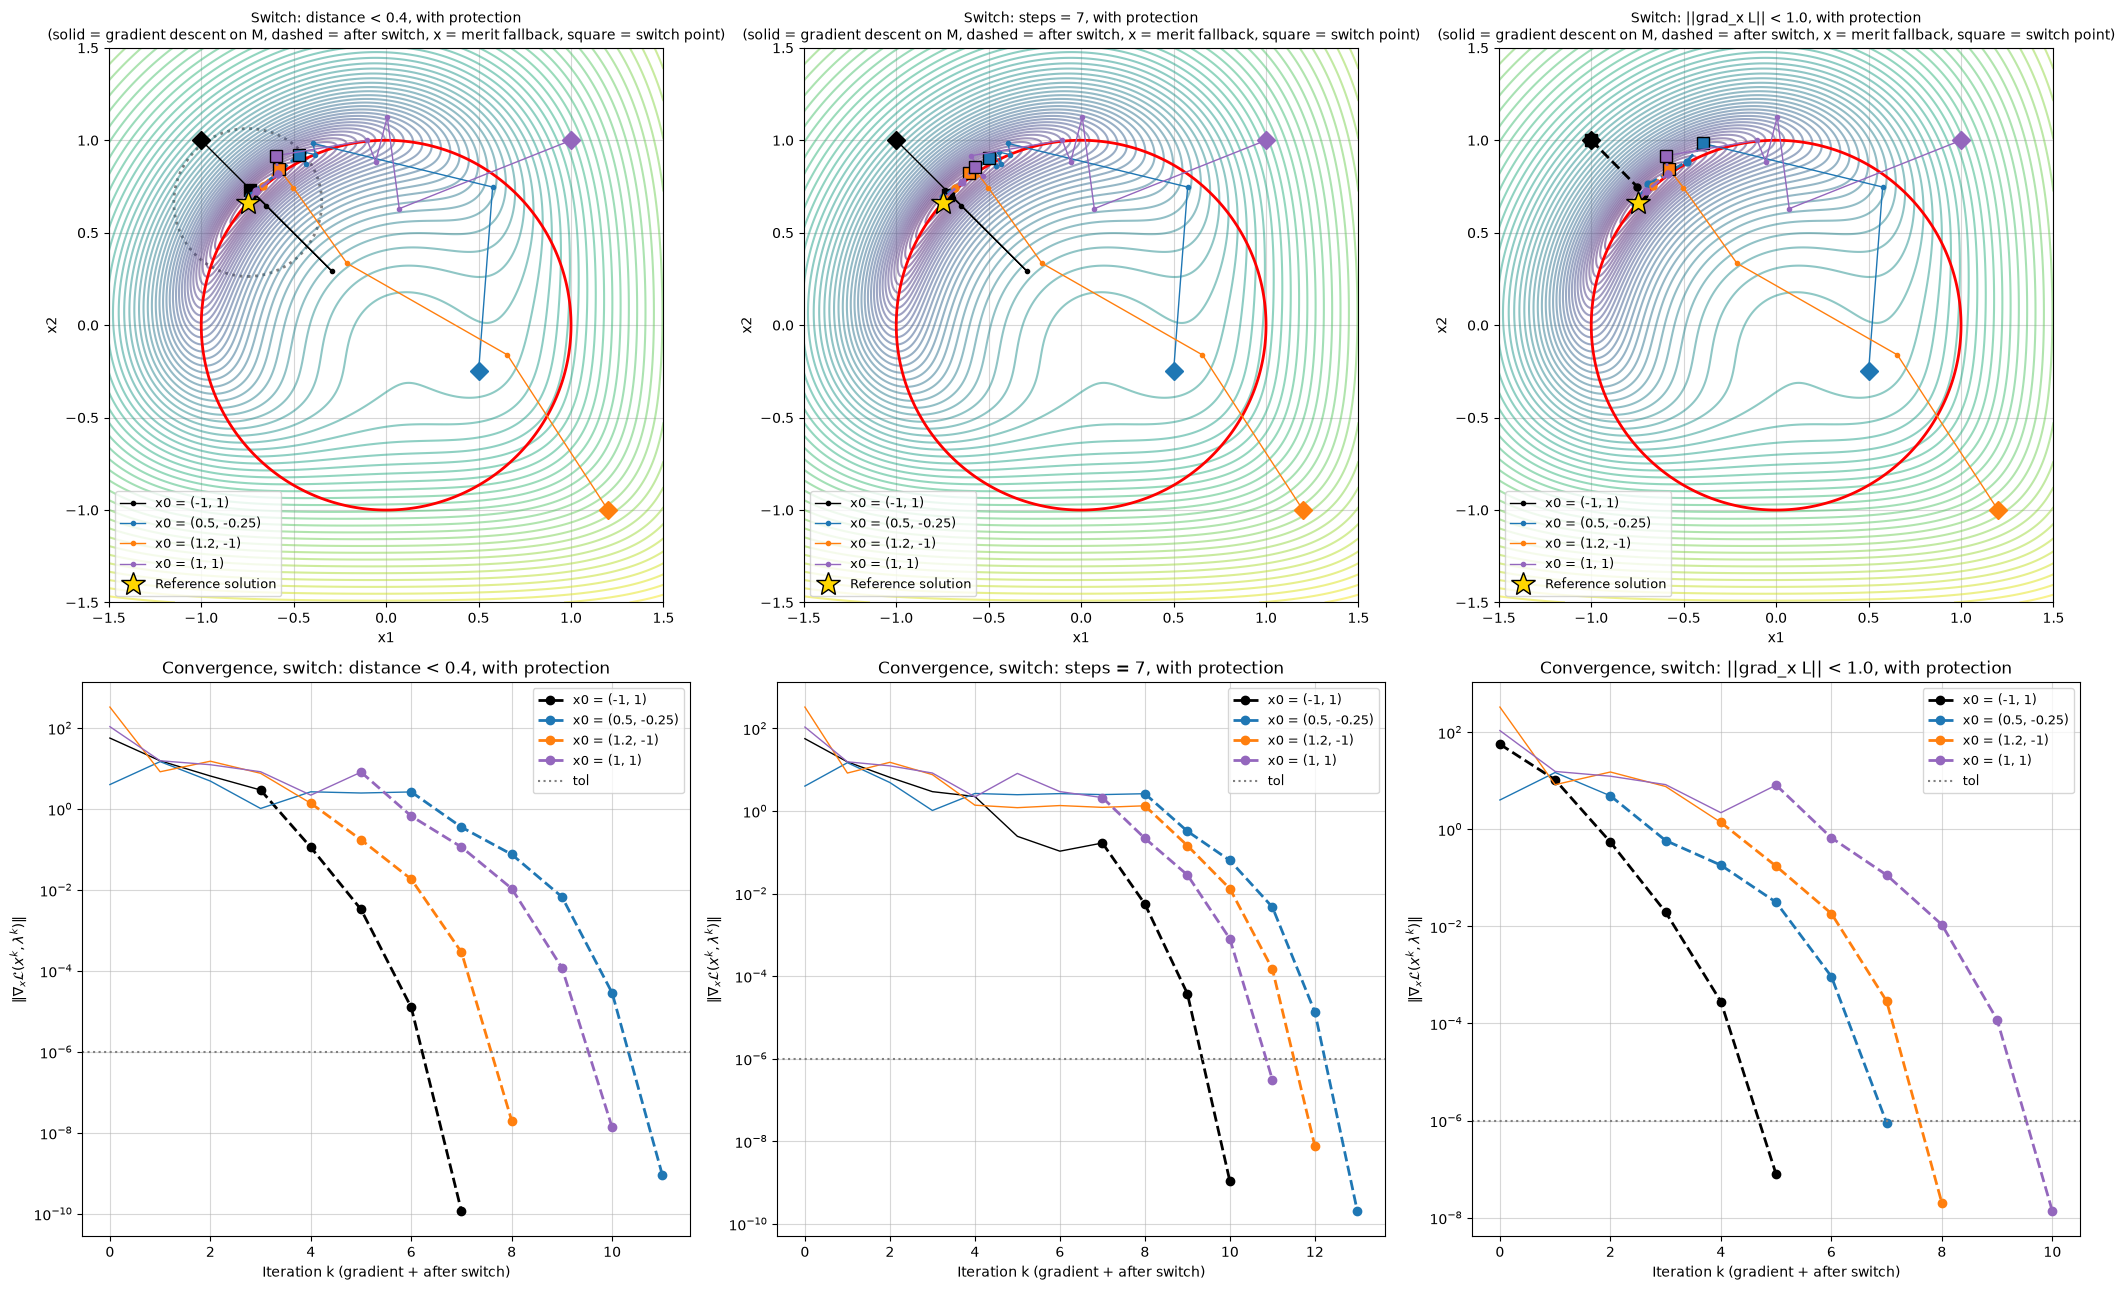

In [21]:
# Claude prompt: make a new cell at the bottom that has the same mechanisms, but if the hessian isn't positive definite, it keeps going with the merit function until it is positive again. call it, merit function + Newton SQP with protection
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

fig, axs = plt.subplots(2, 3, figsize=(21, 13))
for j, (opt, res) in enumerate(results_protected.items()):
    # Paths: solid = gradient descent on M, dashed = after the switch (Newton + merit fallbacks marked with x)
    ax = axs[0, j]
    ax.contour(x1g, x2g, np.log(Mg), levels=60, cmap="viridis", alpha=0.5)
    ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
    if "distance" in opt:
        ax.add_patch(plt.Circle(x_ref, switch_distance, fill=False, ls=":", color="gray", lw=2))
    for name, r in res.items():
        pg, px, ph = r["path_gd"], r["path_x"], r["phases"]
        ax.plot(pg[:, 0], pg[:, 1], "o-", color=colors_sqp[name], ms=3, lw=1, label=f"x0 = {name}")
        ax.plot(px[:, 0], px[:, 1], "o--", color=colors_sqp[name], ms=5, lw=2)
        ax.plot(px[ph == "merit", 0], px[ph == "merit", 1], "x", color=colors_sqp[name], mec="black", ms=10, mew=2)
        ax.plot(*pg[0], "D", color=colors_sqp[name], ms=9)
        ax.plot(*pg[-1], "s", color=colors_sqp[name], mec="black", ms=8)
    ax.plot(*x_ref, "*", color="gold", mec="black", ms=18, zorder=3, label="Reference solution")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f"Switch: {opt}, with protection\n(solid = gradient descent on M, dashed = after switch, x = merit fallback, square = switch point)", fontsize=10)
    ax.grid(alpha=0.5)
    ax.legend(loc="lower left", fontsize=9)

    # Convergence: ||grad_x L|| along the whole run (merit steps use lambda = -2 rho h(x))
    ax = axs[1, j]
    for name, r in res.items():
        pg, ph = r["path_gd"], r["phases"]
        ng_gd = [np.linalg.norm(grad_L(x, lam_merit(x))) for x in pg]
        n_gd = len(pg) - 1
        ks = np.arange(n_gd, n_gd + len(r["norms_gradL"]))
        ax.semilogy(np.arange(n_gd + 1), ng_gd, "-", color=colors_sqp[name], lw=1)
        ax.semilogy(ks, r["norms_gradL"], "o--", color=colors_sqp[name], lw=2, label=f"x0 = {name}")
        ax.semilogy(ks[ph == "merit"], r["norms_gradL"][ph == "merit"], "x", color=colors_sqp[name], mec="black", ms=10, mew=2)
    ax.axhline(1e-6, color="gray", ls=":", label="tol")
    ax.set_xlabel("Iteration k (gradient + after switch)")
    ax.set_ylabel(r"$\|\nabla_x \mathcal{L}(x^k, \lambda^k)\|$")
    ax.set_title(f"Convergence, switch: {opt}, with protection")
    ax.grid(alpha=0.5)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()